# kino.galaxy: the intrinsic disc model

**Scope note.** Like `00_kinms_datacube_demo.ipynb`, this notebook is a
"what works today" demo, not the end-to-end kinematic-lensing showcase
(`02_one_galaxy_inference.ipynb`, still a scaffold pending Phases 2, 3, 5).

This one demonstrates `kino.galaxy` (Phase 1): the intrinsic, **unlensed**
disc model -- `DiscGalaxy`, its Sersic surface brightness, its rotation
curves, and its `Vlos` field. Every cell below actually executes.

We'll:
1. Build a `DiscGalaxy` from physical parameters and render its surface
   brightness, `Vlos`, and velocity-dispersion maps.
2. Compare the three rotation-curve shapes (`arctan`, `tanh`, `flat_turnover`).
3. Show the ellipticity-from-inclination relation and its two limits.
4. Show the face-on (no rotation) and edge-on (major-axis-only) invariants
   that `tests/galaxy/test_disc.py` pins down.
5. Cross-check `DiscGalaxy.vlos` against an independently generated KinMS
   cube -- the same check as
   `tests/galaxy/test_kinms_consistency.py`, done here visually.

No shear anywhere in this notebook -- that's Phase 2. Requires the `data`
extra for the KinMS cross-check: `pip install -e ".[dev,data,notebooks]"`.

## 0. Setup

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import kino
from kino.galaxy import DiscGalaxy
from kino.galaxy.rotation_curve import ROTATION_CURVES

print("kino", kino.__version__)

kino 0.1.0.dev0


## 1. Build a disc and render its maps

`DiscGalaxy` takes physical parameters directly -- no shear, no instrument,
just the intrinsic scene (the very first box in the pipeline diagram in
`README.md`).

In [2]:
gal = DiscGalaxy(
    r_e=3.0,  # Sersic effective radius, arcsec
    inc=55.0,  # degrees; 0 = face-on, 90 = edge-on
    pa=30.0,  # degrees, East of North
    v_flat=180.0,  # asymptotic circular velocity, km/s
    rotation_curve="arctan",
    r_t=2.0,  # rotation-curve turnover radius, arcsec
    sersic_n=1.0,  # 1 = exponential disc
    flux=1.0,
    sigma0=25.0,  # intrinsic velocity dispersion at r=0, km/s
    sigma_grad=-1.5,  # km/s per arcsec
    v_sys=0.0,
)
gal

DiscGalaxy(r_e=3.0, inc=55.0, pa=30.0, v_flat=180.0, z=0.0, sersic_n=1.0, flux=1.0, rotation_curve='arctan', r_t=2.0, x0=0.0, y0=0.0, v_sys=0.0, sigma0=25.0, sigma_grad=-1.5)

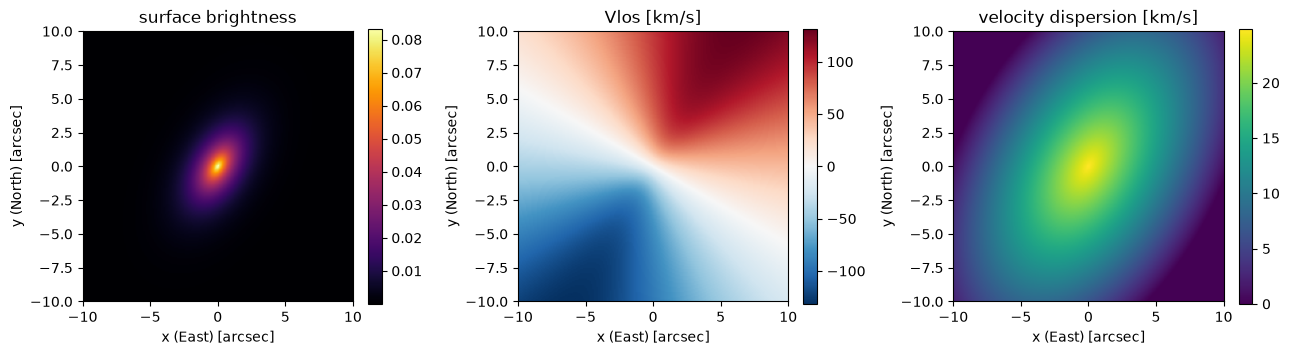

In [3]:
extent = 10.0  # arcsec
coords = np.linspace(-extent, extent, 200)
x, y = np.meshgrid(coords, coords)

flux_map = gal.surface_brightness(x, y)
vel_map = gal.vlos(x, y)
sigma_map = gal.velocity_dispersion(x, y)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

im0 = axes[0].imshow(
    flux_map, origin="lower", extent=[-extent, extent, -extent, extent], cmap="inferno"
)
axes[0].set_title("surface brightness")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

vmax = np.abs(vel_map).max()
im1 = axes[1].imshow(
    vel_map,
    origin="lower",
    extent=[-extent, extent, -extent, extent],
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
)
axes[1].set_title("Vlos [km/s]")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(
    sigma_map, origin="lower", extent=[-extent, extent, -extent, extent], cmap="viridis"
)
axes[2].set_title("velocity dispersion [km/s]")
fig.colorbar(im2, ax=axes[2], fraction=0.046)

for ax in axes:
    ax.set_xlabel("x (East) [arcsec]")
    ax.set_ylabel("y (North) [arcsec]")
fig.tight_layout()

## 2. Rotation-curve shapes

All three satisfy `Vrot(0) = 0` and reach (or asymptote to) `v_flat`; they
differ in how quickly they turn over.

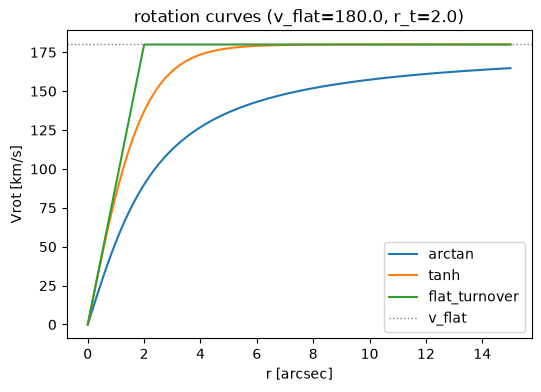

In [4]:
r = np.linspace(0, 15, 300)
v_flat, r_t = 180.0, 2.0

plt.figure(figsize=(6, 4))
for name, model in ROTATION_CURVES.items():
    plt.plot(r, model(r, v_flat, r_t), label=name)
plt.axhline(v_flat, color="gray", ls=":", lw=1, label="v_flat")
plt.xlabel("r [arcsec]")
plt.ylabel("Vrot [km/s]")
plt.legend()
plt.title(f"rotation curves (v_flat={v_flat}, r_t={r_t})");

## 3. Ellipticity from inclination

`eps = (1-q)/(1+q)` with `q = cos(inc)` -- the thin-disc axis ratio. Limits:
face-on (`inc=0`) is circular (`eps=0`); edge-on (`inc=90`) is a line
(`eps=1`).

eps(inc=0)  = 0.0000
eps(inc=90) = 1.0000


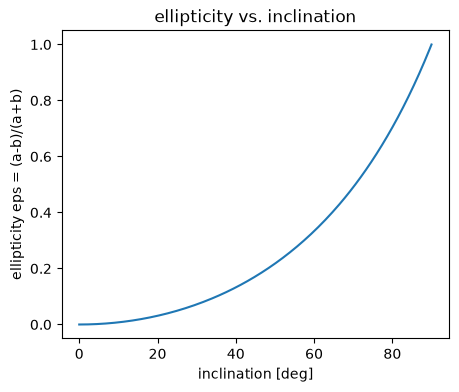

In [5]:
incs = np.linspace(0, 90, 200)
eps = [DiscGalaxy(r_e=1.0, inc=i, pa=0.0, v_flat=100.0).ellipticity for i in incs]

plt.figure(figsize=(5, 4))
plt.plot(incs, eps)
plt.xlabel("inclination [deg]")
plt.ylabel("ellipticity eps = (a-b)/(a+b)")
plt.title("ellipticity vs. inclination")
print(f"eps(inc=0)  = {DiscGalaxy(r_e=1, inc=0, pa=0, v_flat=100).ellipticity:.4f}")
print(f"eps(inc=90) = {DiscGalaxy(r_e=1, inc=90, pa=0, v_flat=100).ellipticity:.4f}")

## 4. Two invariants: face-on and edge-on

**Face-on** (`inc=0`): `sin(inc)=0`, so `Vlos` is `v_sys` everywhere, no
matter the rotation curve or position angle.

**Edge-on** (`inc=90`), on the major axis only: `sin(inc)=1` and
`cos(theta)=+-1` there exactly, so `Vlos - v_sys` equals the rotation curve
itself (with sign flipping on either side of the centroid).

face-on Vlos: min=50.000000, max=50.000000 km/s (v_sys=50.0)


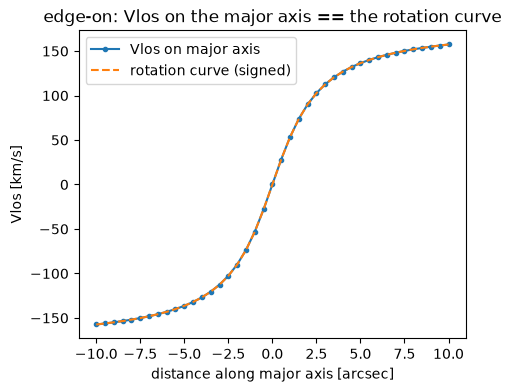

In [6]:
gal_faceon = DiscGalaxy(r_e=3.0, inc=0.0, pa=30.0, v_flat=180.0, v_sys=50.0)
vel_faceon = gal_faceon.vlos(x, y)
print(
    f"face-on Vlos: min={vel_faceon.min():.6f}, max={vel_faceon.max():.6f} km/s "
    f"(v_sys={gal_faceon.v_sys})"
)

gal_edgeon = DiscGalaxy(r_e=3.0, inc=90.0, pa=0.0, v_flat=180.0, r_t=2.0, v_sys=0.0)
d = np.linspace(-10, 10, 41)
pa_rad = np.radians(gal_edgeon.pa)
x_major = gal_edgeon.x0 + d * np.sin(pa_rad)
y_major = gal_edgeon.y0 + d * np.cos(pa_rad)
vel_major = gal_edgeon.vlos(x_major, y_major)

plt.figure(figsize=(5, 4))
plt.plot(d, vel_major, "o-", ms=3, label="Vlos on major axis")
plt.plot(
    d,
    np.sign(d) * ROTATION_CURVES["arctan"](np.abs(d), gal_edgeon.v_flat, gal_edgeon.r_t),
    "--",
    label="rotation curve (signed)",
)
plt.xlabel("distance along major axis [arcsec]")
plt.ylabel("Vlos [km/s]")
plt.legend()
plt.title("edge-on: Vlos on the major axis == the rotation curve");

## 5. Cross-check against an independent KinMS cube

`kino.galaxy` and `kino.io.kinms` (Tier A of `TEST_DATA.md`) were built
independently, each deriving the East-of-North position-angle convention
from scratch. `tests/galaxy/test_kinms_consistency.py` checks they agree;
here's the same comparison, visually.

In [7]:
from kino.galaxy.rotation_curve import arctan
from kino.io.kinms import generate_disc_cube

inc, pa, v_flat, r_t = 60.0, 40.0, 180.0, 3.0
pixel_scale = 1.0  # arcsec

gal_cmp = DiscGalaxy(r_e=3.0, inc=inc, pa=pa, v_flat=v_flat, r_t=r_t, rotation_curve="arctan")

vel_rad = np.linspace(0, 15, 30)
cube = generate_disc_cube(
    field_of_view=30 * u.arcsec,
    pixel_scale=pixel_scale * u.arcsec,
    velocity_range=500 * u.km / u.s,
    channel_width=10 * u.km / u.s,
    beam_size=1 * u.arcsec,
    inc=inc,
    pa=pa,
    sb_rad=[0, 5, 10, 15] * u.arcsec,
    sb_prof=[1.0, 0.6, 0.2, 0.0],
    vel_rad=vel_rad * u.arcsec,
    vel_prof=arctan(vel_rad, v_flat, r_t) * u.km / u.s,
    gas_sigma=5 * u.km / u.s,
    n_clouds=300_000,
    rng=np.random.default_rng(3),
)

v = cube.spectral_axis.to_value(u.km / u.s)[:, None, None]
flux_map_kinms = cube.flux.sum(axis=0)
with np.errstate(invalid="ignore", divide="ignore"):
    vel_map_kinms = (cube.flux * v).sum(axis=0) / flux_map_kinms
signal = flux_map_kinms > 0.1 * flux_map_kinms.max()

ny, nx = flux_map_kinms.shape
coords_cmp = (np.arange(nx) - nx // 2) * pixel_scale
x_cmp, y_cmp = np.meshgrid(coords_cmp, coords_cmp)
vel_map_analytic = gal_cmp.vlos(x_cmp, y_cmp)

correlation = np.corrcoef(vel_map_kinms[signal], vel_map_analytic[signal])[0, 1]
print(f"Vlos-map correlation (KinMS vs. DiscGalaxy): {correlation:.5f}")

Vlos-map correlation (KinMS vs. DiscGalaxy): 0.99990


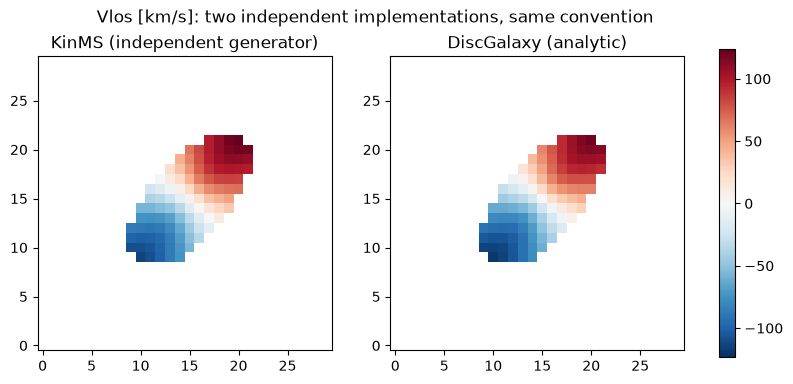

In [8]:
vmax = np.nanmax(np.abs(np.where(signal, vel_map_kinms, np.nan)))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(
    np.where(signal, vel_map_kinms, np.nan), origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax
)
axes[0].set_title("KinMS (independent generator)")
im1 = axes[1].imshow(
    np.where(signal, vel_map_analytic, np.nan), origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax
)
axes[1].set_title("DiscGalaxy (analytic)")
fig.colorbar(im1, ax=axes, fraction=0.023)
fig.suptitle("Vlos [km/s]: two independent implementations, same convention");

## What's next

- `kino.lensing` (Phase 2): apply a shear `(g1, g2)` to this `DiscGalaxy`
  scene -- both the surface brightness *and* the `Vlos` field.
- `kino.instruments` (Phase 3): turn the sheared scene into a realistic mock
  observation (IFU datacube, or slit/grism spectrum + image).
- `kino.inference` (Phase 5): recover `(g1, g2)` back out with `nautilus`.

Once those land, `02_one_galaxy_inference.ipynb` becomes the real
end-to-end story; this notebook stays as the `kino.galaxy` reference/demo.